In [ ]:
#Assignment_7

In [4]:
#Q1
import re
import string
from collections import Counter

import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
from nltk import pos_tag, word_tokenize
from nltk.corpus import wordnet
from nltk.stem import LancasterStemmer, PorterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.tokenize import RegexpTokenizer

for resource in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
                 "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(resource, quiet=True)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 80)

# --- Define your datasets here ---
tickets = [
    "Hello! This is a sample support ticket with some punctuation.",
    "Another example ticket to test processing."
]
TEST_LINES = [
    "Please contact us at support@example.com or call +1-555-0199.",
    "You can also visit our site at www.example.com for more info."
]

# --- Define your preprocessing function here ---
def process_ticket(ticket_text):
    sentences = nltk.sent_tokenize(ticket_text)
    tokens = nltk.word_tokenize(ticket_text)
    punctuation = [char for char in ticket_text if char in string.punctuation]
    stopwords = [w for w in tokens if w.lower() in nltk.corpus.stopwords.words('english')]
    final = [w for w in tokens if w.isalnum() and w.lower() not in nltk.corpus.stopwords.words('english')]
    return sentences, tokens, punctuation, stopwords, final

tickets = list(tickets)
TEST_LINES = list(TEST_LINES)


def banner(title):
    print("\n" + "=" * 100)
    print(title)
    print("=" * 100)


def count_of(value):
    if isinstance(value, (int, np.integer)):
        return int(value)
    return len(value)


def as_list(value):
    if isinstance(value, (int, np.integer)):
        return []
    return list(value)


def unpack(result):
    if isinstance(result, dict):
        fields = result
    elif hasattr(result, "__dict__"):
        fields = vars(result)
    else:
        fields = None
    if fields is not None:
        def find(include, exclude=()):
            for key in fields:
                name = str(key).lower()
                if any(w in name for w in include) and not any(w in name for w in exclude):
                    return fields[key]
            raise KeyError(f"process_ticket output has fields {list(fields)}; edit unpack() to map them")
        return {
            "sentences": find(["sent"]),
            "tokens": find(["token", "word"], ["final", "punct", "stop", "unique", "clean", "filter", "lemma", "stem"]),
            "punctuation": find(["punct"]),
            "stopwords": find(["stop"]),
            "final": find(["final", "clean", "filter", "lemma", "stem", "processed"]),
        }
    sentences, tokens, punctuation, stopword_list, final = list(result)[:5]
    return {"sentences": sentences, "tokens": tokens, "punctuation": punctuation,
            "stopwords": stopword_list, "final": final}


processed = [unpack(process_ticket(t)) for t in tickets]


banner("QUESTION 1: PREPROCESSING")

rows = []
for i, p in enumerate(processed, 1):
    toks = as_list(p["tokens"])
    rows.append({
        "Ticket": f"T{i}",
        "Sentences": count_of(p["sentences"]),
        "Tokens": count_of(p["tokens"]),
        "Punctuation": count_of(p["punctuation"]),
        "Stopwords": count_of(p["stopwords"]),
        "Unique tokens": len(set(toks)),
        "Final tokens": count_of(p["final"]),
    })
table1 = pd.DataFrame(rows)
total_row = {"Ticket": "TOTAL"}
for col in table1.columns[1:]:
    total_row[col] = int(table1[col].sum())
table1 = pd.concat([table1, pd.DataFrame([total_row])], ignore_index=True)
print(table1.to_string(index=False))

SELECTED = 0
sel = processed[SELECTED]
print(f"\nSelected ticket: T{SELECTED + 1}")
print("Raw text         :", tickets[SELECTED])
print("Tokens           :", as_list(sel["tokens"]))
print("Punctuation      :", as_list(sel["punctuation"]))
print("Stopwords        :", as_list(sel["stopwords"]))
print("Final tokens     :", as_list(sel["final"]))



QUESTION 1: PREPROCESSING
Ticket  Sentences  Tokens  Punctuation  Stopwords  Unique tokens  Final tokens
    T1          2      12            2          5             12             5
    T2          1       7            1          1              7             5
 TOTAL          3      19            3          6             19            10

Selected ticket: T1
Raw text         : Hello! This is a sample support ticket with some punctuation.
Tokens           : ['Hello', '!', 'This', 'is', 'a', 'sample', 'support', 'ticket', 'with', 'some', 'punctuation', '.']
Punctuation      : ['!', '.']
Stopwords        : ['This', 'is', 'a', 'with', 'some']
Final tokens     : ['Hello', 'sample', 'support', 'ticket', 'punctuation']


In [7]:
#Q2
import re
import string
from collections import Counter

import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
from nltk import pos_tag, word_tokenize
from nltk.corpus import wordnet
from nltk.stem import LancasterStemmer, PorterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.tokenize import RegexpTokenizer

for resource in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
                 "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(resource, quiet=True)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 80)


def banner(title):
    print("\n" + "=" * 100)
    print(title)
    print("=" * 100)


def count_of(value):
    if isinstance(value, (int, np.integer)):
        return int(value)
    return len(value)


def as_list(value):
    if isinstance(value, (int, np.integer)):
        return []
    return list(value)


def unpack(result):
    if isinstance(result, dict):
        fields = result
    elif hasattr(result, "__dict__"):
        fields = vars(result)
    else:
        fields = None
    if fields is not None:
        def find(include, exclude=()):
            for key in fields:
                name = str(key).lower()
                if any(w in name for w in include) and not any(w in name for w in exclude):
                    return fields[key]
            raise KeyError(f"process_ticket output has fields {list(fields)}; edit unpack() to map them")
        return {
            "sentences": find(["sent"]),
            "tokens": find(["token", "word"], ["final", "punct", "stop", "unique", "clean", "filter", "lemma", "stem"]),
            "punctuation": find(["punct"]),
            "stopwords": find(["stop"]),
            "final": find(["final", "clean", "filter", "lemma", "stem", "processed"]),
        }
    sentences, tokens, punctuation, stopword_list, final = list(result)[:5]
    return {"sentences": sentences, "tokens": tokens, "punctuation": punctuation,
            "stopwords": stopword_list, "final": final}


banner("QUESTION 2: REGEX EXTRACTION AND REPLACEMENT")

RE_LONG_WORDS = re.compile(r"\b[A-Za-z]{6,}\b")
RE_NUMBERS = re.compile(r"(?<![\d.])\d+(?:\.\d+)*")
RE_CAPITALIZED = re.compile(r"\b[A-Z][a-z]+\b")
RE_VOWEL_WORDS = re.compile(r"\b[aeiouAEIOU][A-Za-z]*(?:'[A-Za-z]+)?\b")

RE_EMAIL = re.compile(r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+")
RE_URL = re.compile(r"(?:https?://|www\.)[^\s<>\"']*[^\s<>\"'.,;:!?)\]]")
RE_PHONE = re.compile(
    r"(?<![\w.])(?:\+?\d{1,3}[\s.-]?)?(?:\(\d{3}\)|\d{3})[\s.-]?\d{3}[\s.-]?\d{4}(?![\w])"
    r"|(?<![\w.])(?:\+91[\s-]?)?\d{5}[\s-]?\d{5}(?![\w])"
)


def mask(text):
    text = RE_EMAIL.sub("<EMAIL>", text)
    text = RE_URL.sub("<URL>", text)
    text = RE_PHONE.sub("<PHONE>", text)
    return text


extractors = {
    "Words longer than 5 letters": RE_LONG_WORDS,
    "Numbers (decimals / versions kept whole)": RE_NUMBERS,
    "Capitalized words": RE_CAPITALIZED,
    "Words beginning with a vowel": RE_VOWEL_WORDS,
}

print("\n--- re.findall on TEST_LINES ---")
for line in TEST_LINES:
    print("\nLINE:", line)
    for name, rx in extractors.items():
        print(f"  {name:<42}: {re.findall(rx, line)}")

print("\n--- re.findall on all raw tickets (per ticket) ---")
for name, rx in extractors.items():
    print(f"\n{name}")
    for i, t in enumerate(tickets, 1):
        print(f"  T{i:<2}: {re.findall(rx, t)}")

print("\n--- re.sub on TEST_LINES ---")
for line in TEST_LINES:
    print("BEFORE:", line)
    print("AFTER :", mask(line))
    print()

print("--- re.sub on all raw tickets ---")
for i, t in enumerate(tickets, 1):
    print(f"T{i} BEFORE:", t)
    print(f"T{i} AFTER :", mask(t))
    print()



QUESTION 2: REGEX EXTRACTION AND REPLACEMENT

--- re.findall on TEST_LINES ---

LINE: Please contact us at support@example.com or call +1-555-0199.
  Words longer than 5 letters               : ['Please', 'contact', 'support', 'example']
  Numbers (decimals / versions kept whole)  : ['1', '555', '0199']
  Capitalized words                         : ['Please']
  Words beginning with a vowel              : ['us', 'at', 'example', 'or']

LINE: You can also visit our site at www.example.com for more info.
  Words longer than 5 letters               : ['example']
  Numbers (decimals / versions kept whole)  : []
  Capitalized words                         : ['You']
  Words beginning with a vowel              : ['also', 'our', 'at', 'example', 'info']

--- re.findall on all raw tickets (per ticket) ---

Words longer than 5 letters
  T1 : ['sample', 'support', 'ticket', 'punctuation']
  T2 : ['Another', 'example', 'ticket', 'processing']

Numbers (decimals / versions kept whole)
  T1 : []
  T

In [9]:
#Q3
import re
import string
from collections import Counter

import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
from nltk import pos_tag, word_tokenize
from nltk.corpus import wordnet
from nltk.stem import LancasterStemmer, PorterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.tokenize import RegexpTokenizer

for resource in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
                 "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(resource, quiet=True)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 80)

def banner(title):
    print("\n" + "=" * 100)
    print(title)
    print("=" * 100)

EMAIL_P = r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+"
URL_P = r"(?:https?://|www\.)[^\s<>\"']*[^\s<>\"'.,;:!?)\"']"
PHONE_P = (r"(?:\+?\d{1,3}[\s.-]?)?(?:\(\d{3}\)|\d{3})[\s.-]?\d{3}[\s.-]?\d{4}(?![\w])"
           r"|(?:\+91[\s-]?)?\d{5}[\s-]?\d{5}(?![\w])")
VERSION_P = r"[vV]?\d+(?:\.\d+)+"
HYPHEN_P = r"[A-Za-z]+(?:-[A-Za-z0-9]+)+"
CONTRACTION_P = r"[A-Za-z]+(?:['\u2019][A-Za-z]+)+"
WORD_P = r"[A-Za-z0-9_]+"
PUNCT_P = r"[^\w\s]"

TOKEN_PATTERN = "|".join([
    EMAIL_P, URL_P, rf"(?<![\w.])(?:{PHONE_P})", VERSION_P, HYPHEN_P, CONTRACTION_P, WORD_P, PUNCT_P,
])

_tokenizer = RegexpTokenizer(TOKEN_PATTERN)


def my_tokenize(text):
    return _tokenizer.tokenize(text)


def classify(token):
    if "@" in token:
        return "email"
    if re.match(r"(?i)(https?://|www\.)", token):
        return "url"
    if re.fullmatch(PHONE_P, token):
        return "phone"
    if re.fullmatch(CONTRACTION_P, token):
        return "contraction"
    if re.fullmatch(VERSION_P, token):
        return "version/decimal"
    if re.fullmatch(HYPHEN_P, token):
        return "hyphenated"
    return "other"


EXPLANATIONS = {
    "email": "word_tokenize follows Penn Treebank rules, which know nothing about e-mail syntax, so the address is cut at '@' and \".\".'; my pattern tries the e-mail alternative first and keeps the whole address as one token.",
    "url": "word_tokenize splits a URL at ':', '//', '?', '=' and similar characters, losing the link; my pattern keeps the full URL as one token (trailing sentence punctuation is excluded).",
    "phone": "word_tokenize separates the parentheses and spaces of a phone number into several tokens; my pattern keeps the complete number together as a single token.",
    "contraction": "word_tokenize splits clitics (is + n't), so the negation becomes a separate token; my pattern keeps the contraction as one word, which preserves the original word form.",
    "version/decimal": "word_tokenize may detach a trailing symbol or prefix (for example '%' or 'v'); my pattern keeps decimals and version strings such as 2.0.1 exactly as written.",
    "hyphenated": "my pattern explicitly keeps hyphenated compounds as one token.",
    "other": "the two tokenizers apply different splitting rules for this token.",
}

all_texts = TEST_LINES + tickets
examples = {}
for text in all_texts:
    mine = my_tokenize(text)
    theirs = word_tokenize(text)
    only_mine = Counter(mine) - Counter(theirs)
    only_nltk = Counter(theirs) - Counter(mine)
    for tok in only_mine:
        cat = classify(tok)
        if cat not in examples:
            examples[cat] = (text, tok, word_tokenize(tok))

banner("QUESTION 3: CUSTOM TOKENIZATION")

print("TOKEN_PATTERN =")
print(TOKEN_PATTERN)

print("\n--- my_tokenize on TEST_LINES ---")
for line in TEST_LINES:
    print("\nLINE   :", line)
    print("TOKENS :", my_tokenize(line))

print("\n--- my_tokenize on tickets ---")
for i, t in enumerate(tickets, 1):
    print(f"\nT{i} TOKENS: {my_tokenize(t)}")


print("\n--- Differences between my_tokenize and word_tokenize ---")
for n, (cat, (text, tok, pieces)) in enumerate(examples.items(), 1):
    print(f"\nDifference {n}: {cat}")
    print("  Text            :", text)
    print("  my_tokenize     :", tok)
    print("  word_tokenize   :", pieces)
    print("  Why             :", EXPLANATIONS[cat])

print("\nTotal tokens over TEST_LINES + tickets:",
      "my_tokenize =", sum(len(my_tokenize(t)) for t in all_texts),
      "| word_tokenize =", sum(len(word_tokenize(t)) for t in all_texts))



QUESTION 3: CUSTOM TOKENIZATION
TOKEN_PATTERN =
[\w.+-]+@[\w-]+(?:\.[\w-]+)+|(?:https?://|www\.)[^\s<>\"']*[^\s<>\"'.,;:!?)\"']|(?<![\w.])(?:(?:\+?\d{1,3}[\s.-]?)?(?:\(\d{3}\)|\d{3})[\s.-]?\d{3}[\s.-]?\d{4}(?![\w])|(?:\+91[\s-]?)?\d{5}[\s-]?\d{5}(?![\w]))|[vV]?\d+(?:\.\d+)+|[A-Za-z]+(?:-[A-Za-z0-9]+)+|[A-Za-z]+(?:['\u2019][A-Za-z]+)+|[A-Za-z0-9_]+|[^\w\s]

--- my_tokenize on TEST_LINES ---

LINE   : Please contact us at support@example.com or call +1-555-0199.
TOKENS : ['Please', 'contact', 'us', 'at', 'support@example.com', 'or', 'call', '+', '1', '-', '555', '-', '0199', '.']

LINE   : You can also visit our site at www.example.com for more info.
TOKENS : ['You', 'can', 'also', 'visit', 'our', 'site', 'at', 'www.example.com', 'for', 'more', 'info', '.']

--- my_tokenize on tickets ---

T1 TOKENS: ['Hello', '!', 'This', 'is', 'a', 'sample', 'support', 'ticket', 'with', 'some', 'punctuation', '.']

T2 TOKENS: ['Another', 'example', 'ticket', 'to', 'test', 'processing', '.']

--- Diffe

In [10]:
#Q4
import re
import string
from collections import Counter

import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
from nltk import pos_tag, word_tokenize
from nltk.corpus import wordnet
from nltk.stem import LancasterStemmer, PorterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.tokenize import RegexpTokenizer

for resource in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
                 "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(resource, quiet=True)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 80)

# Re-definitions of tickets and TEST_LINES removed to prevent NameError.

def banner(title):
    print("\n" + "=" * 100)
    print(title)
    print("=" * 100)


def count_of(value):
    if isinstance(value, (int, np.integer)):
        return int(value)
    return len(value)


def as_list(value):
    if isinstance(value, (int, np.integer)):
        return []
    return list(value)


def unpack(result):
    if isinstance(result, dict):
        fields = result
    elif hasattr(result, "__dict__"):
        fields = vars(result)
    else:
        fields = None
    if fields is not None:
        def find(include, exclude=()):
            for key in fields:
                name = str(key).lower()
                if any(w in name for w in include) and not any(w in name for w in exclude):
                    return fields[key]
            raise KeyError(f"process_ticket output has fields {list(fields)}; edit unpack() to map them")
        return {
            "sentences": find(["sent"]),
            "tokens": find(["token", "word"], ["final", "punct", "stop", "unique", "clean", "filter", "lemma", "stem"]),
            "punctuation": find(["punct"]),
            "stopwords": find(["stop"]),
            "final": find(["final", "clean", "filter", "lemma", "stem", "processed"]),
        }
    sentences, tokens, punctuation, stopword_list, final = list(result)[:5]
    return {"sentences": sentences, "tokens": tokens, "punctuation": punctuation,
            "stopwords": stopword_list, "final": final}


processed = [unpack(process_ticket(t)) for t in tickets]


unique_final = sorted({w for p in processed for w in as_list(p["final"])})
porter = PorterStemmer()
lancaster = LancasterStemmer()
lemmatizer = WordNetLemmatizer()


def wn_pos(tag):
    if tag.startswith("J"):
        return wordnet.ADJ
    if tag.startswith("V"):
        return wordnet.VERB
    if tag.startswith("R"):
        return wordnet.ADV
    return wordnet.NOUN


pos_votes = {}
for p in processed:
    final = as_list(p["final"])
    if not final:
        continue
    for word, tag in pos_tag(final):
        pos_votes.setdefault(word, Counter())[tag] += 1
word_tag = {w: pos_votes[w].most_common(1)[0][0] for w in unique_final if w in pos_votes}
for w in unique_final:
    word_tag.setdefault(w, pos_tag([w])[0][1])

candidate_suffixes = ["ing", "ed", "ion", "ly", "ment", "er", "able"]
suffix_words = {s: [w for w in unique_final if w.endswith(s) and len(w) - len(s) >= 3] for s in candidate_suffixes}
usable = {s: ws for s, ws in suffix_words.items() if len(ws) >= 2}
chosen = max(usable, key=lambda s: len(usable[s])) if usable else "s"
chosen_words = usable.get(chosen, [w for w in unique_final if w.endswith("s")][:3])
regexp_stemmer = RegexpStemmer(chosen + "$", min=4)

rows = []
for w in unique_final:
    tag = word_tag[w]
    rows.append({
        "Word": w,
        "POS": tag,
        "Porter": porter.stem(w),
        "Lancaster": lancaster.stem(w),
        "Regexp": regexp_stemmer.stem(w),
        "WordNet Lemma": lemmatizer.lemmatize(w, wn_pos(tag)),
    })
all_outputs = pd.DataFrame(rows)
differ = all_outputs[all_outputs[["Porter", "Lancaster", "Regexp", "WordNet Lemma"]].nunique(axis=1) > 1]


banner("QUESTION 4: STEMMING AND LEMMATIZATION")

print("Unique final tokens:", len(unique_final))
print(f"\nSuffix counts in dataset: { {s: len(w) for s, w in suffix_words.items()} }")
print(f"Chosen Regexp Stemmer suffix: '{chosen}'")
print(f"Supporting words from this dataset: {chosen_words}")
print(f"Justification: '{chosen}' is the most frequent derivational/inflectional ending among the unique final tokens "
      f"({len(chosen_words)} words, e.g. {', '.join(chosen_words[:3])}), so stripping it normalises the most words, and the "
      f"min=4 setting stops very short words from being cut.")

print(f"\nWords where the four outputs differ: {len(differ)} of {len(all_outputs)}")
print(differ.to_string(index=False))



QUESTION 4: STEMMING AND LEMMATIZATION
Unique final tokens: 9

Suffix counts in dataset: {'ing': 1, 'ed': 0, 'ion': 1, 'ly': 0, 'ment': 0, 'er': 1, 'able': 0}
Chosen Regexp Stemmer suffix: 's'
Supporting words from this dataset: []
Justification: 's' is the most frequent derivational/inflectional ending among the unique final tokens (0 words, e.g. ), so stripping it normalises the most words, and the min=4 setting stops very short words from being cut.

Words where the four outputs differ: 6 of 9
       Word POS   Porter Lancaster      Regexp WordNet Lemma
    Another  DT    anoth     anoth     Another       Another
      Hello NNP    hello     hello       Hello         Hello
    example  NN   exampl    exampl     example       example
 processing  NN  process   process  processing    processing
punctuation  NN punctuat    punctu punctuation   punctuation
     sample  JJ    sampl     sampl      sample        sample



QUESTION 5: CORPUS STATISTICS
                Set  Total tokens  Unique tokens    TTR
    S1 (all tokens)            19             17 0.8947
S2 (no punctuation)            16             15 0.9375
  S3 (final tokens)            10              9 0.9000
   S4 (S3 + Porter)            10              9 0.9000

Top 10 words of S1:
   Word  Frequency
 ticket          2
      .          2
  Hello          1
      !          1
   This          1
     is          1
      a          1
 sample          1
support          1
   with          1

Top 10 words of S3:
       Word  Frequency
     ticket          2
      Hello          1
     sample          1
    support          1
punctuation          1
    Another          1
    example          1
       test          1
 processing          1

Zipf fit for S3: log10(freq) = -0.238 * log10(rank) + 0.181


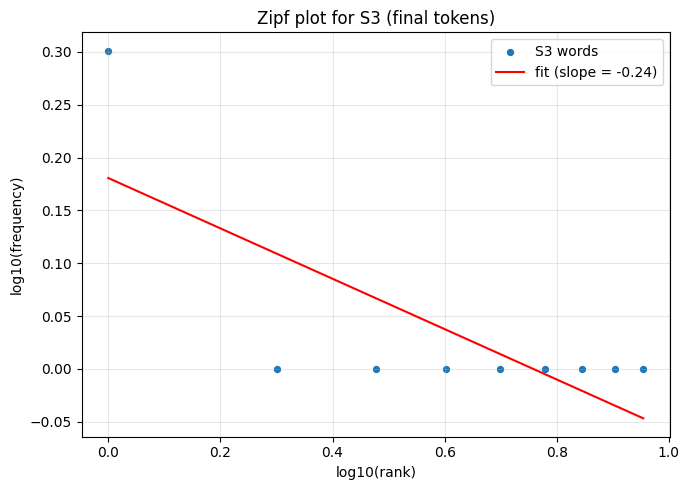


Top 5 bigrams of S1:
  ('Hello', '!'): 1
  ('!', 'This'): 1
  ('This', 'is'): 1
  ('is', 'a'): 1
  ('a', 'sample'): 1

Top 5 bigrams of S3:
  ('Hello', 'sample'): 1
  ('sample', 'support'): 1
  ('support', 'ticket'): 1
  ('ticket', 'punctuation'): 1
  ('Another', 'example'): 1


In [11]:
#Q5
import re
import string
from collections import Counter

import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
from nltk import pos_tag, word_tokenize
from nltk.corpus import wordnet
from nltk.stem import LancasterStemmer, PorterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.tokenize import RegexpTokenizer

for resource in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
                 "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(resource, quiet=True)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 80)

# Re-definitions of tickets and TEST_LINES removed to prevent NameError.


def banner(title):
    print("\n" + "=" * 100)
    print(title)
    print("=" * 100)


def count_of(value):
    if isinstance(value, (int, np.integer)):
        return int(value)
    return len(value)


def as_list(value):
    if isinstance(value, (int, np.integer)):
        return []
    return list(value)


def unpack(result):
    if isinstance(result, dict):
      fields = result
    elif hasattr(result, "__dict__"):
      fields = vars(result)
    else:
      fields = None
    if fields is not None:
        def find(include, exclude=()):
            for key in fields:
                name = str(key).lower()
                if any(w in name for w in include) and not any(w in name for w in exclude):
                    return fields[key]
            raise KeyError(f"process_ticket output has fields {list(fields)}; edit unpack() to map them")
        return {
            "sentences": find(["sent"]),
            "tokens": find(["token", "word"], ["final", "punct", "stop", "unique", "clean", "filter", "lemma", "stem"]),
            "punctuation": find(["punct"]),
            "stopwords": find(["stop"]),
            "final": find(["final", "clean", "filter", "lemma", "stem", "processed"]),
        }
    sentences, tokens, punctuation, stopword_list, final = list(result)[:5]
    return {"sentences": sentences, "tokens": tokens, "punctuation": punctuation,
            "stopwords": stopword_list, "final": final}


processed = [unpack(process_ticket(t)) for t in tickets]


unique_final = sorted({w for p in processed for w in as_list(p["final"])})
porter = PorterStemmer()
lancaster = LancasterStemmer()
lemmatizer = WordNetLemmatizer()


def wn_pos(tag):
    if tag.startswith("J"):
        return wordnet.ADJ
    if tag.startswith("V"):
        return wordnet.VERB
    if tag.startswith("R"):
        return wordnet.ADV
    return wordnet.NOUN


pos_votes = {}
for p in processed:
    final = as_list(p["final"])
    if not final:
        continue
    for word, tag in pos_tag(final):
        pos_votes.setdefault(word, Counter())[tag] += 1
word_tag = {w: pos_votes[w].most_common(1)[0][0] for w in unique_final if w in pos_votes}
for w in unique_final:
    word_tag.setdefault(w, pos_tag([w])[0][1])

candidate_suffixes = ["ing", "ed", "ion", "ly", "ment", "er", "able"]
suffix_words = {s: [w for w in unique_final if w.endswith(s) and len(w) - len(s) >= 3] for s in candidate_suffixes}
usable = {s: ws for s, ws in suffix_words.items() if len(ws) >= 2}
chosen = max(usable, key=lambda s: len(usable[s])) if usable else "s"
chosen_words = usable.get(chosen, [w for w in unique_final if w.endswith("s")][:3])
regexp_stemmer = RegexpStemmer(chosen + "$", min=4)

rows = []
for w in unique_final:
    tag = word_tag[w]
    rows.append({
        "Word": w,
        "POS": tag,
        "Porter": porter.stem(w),
        "Lancaster": lancaster.stem(w),
        "Regexp": regexp_stemmer.stem(w),
        "WordNet Lemma": lemmatizer.lemmatize(w, wn_pos(tag)),
    })
all_outputs = pd.DataFrame(rows)
differ = all_outputs[all_outputs[["Porter", "Lancaster", "Regexp", "WordNet Lemma"]].nunique(axis=1) > 1]


def is_punct(tok):
    return not any(ch.isalnum() for ch in tok)


tokens_s1 = [t for p in processed for t in as_list(p["tokens"])]
tokens_s2 = [t for t in tokens_s1 if not is_punct(t)]
tokens_s3 = [t for p in processed for t in as_list(p["final"])]
tokens_s4 = [porter.stem(t) for t in tokens_s3]

series = {"S1 (all tokens)": tokens_s1, "S2 (no punctuation)": tokens_s2,
          "S3 (final tokens)": tokens_s3, "S4 (S3 + Porter)": tokens_s4}

stat_rows = []
for name, toks in series.items():
    total, unique = len(toks), len(set(toks))
    stat_rows.append({"Set": name, "Total tokens": total, "Unique tokens": unique, "TTR": round(unique / total, 4)})
stats = pd.DataFrame(stat_rows)
freq_s1 = Counter(tokens_s1)
freq_s3 = Counter(tokens_s3)

banner("QUESTION 5: CORPUS STATISTICS")


print(stats.to_string(index=False))

print("\nTop 10 words of S1:")
print(pd.DataFrame(freq_s1.most_common(10), columns=["Word", "Frequency"]).to_string(index=False))
print("\nTop 10 words of S3:")
print(pd.DataFrame(freq_s3.most_common(10), columns=["Word", "Frequency"]).to_string(index=False))

ranked = freq_s3.most_common()
ranks = np.arange(1, len(ranked) + 1)
freqs = np.array([f for _, f in ranked])
log_rank, log_freq = np.log10(ranks), np.log10(freqs)
slope, intercept = np.polyfit(log_rank, log_freq, 1)
print(f"\nZipf fit for S3: log10(freq) = {slope:.3f} * log10(rank) + {intercept:.3f}")

plt.figure(figsize=(7, 5))
plt.scatter(log_rank, log_freq, s=18, label="S3 words")
plt.plot(log_rank, slope * log_rank + intercept, color="red", label=f"fit (slope = {slope:.2f})")
plt.xlabel("log10(rank)")
plt.ylabel("log10(frequency)")
plt.title("Zipf plot for S3 (final tokens)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("zipf_s3.png", dpi=150)
plt.show()


def top_bigrams(token_lists, n=5):
    counter = Counter()
    for toks in token_lists:
        counter.update(nltk.bigrams(toks))
    return counter.most_common(n)


print("\nTop 5 bigrams of S1:")
for bg, c in top_bigrams([as_list(p["tokens"]) for p in processed]):
    print(f"  {bg}: {c}")
print("\nTop 5 bigrams of S3:")
for bg, c in top_bigrams([as_list(p["final"]) for p in processed]):
    print(f"  {bg}: {c}")

In [13]:
#Q6
import re
import string
from collections import Counter

import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
from nltk import pos_tag, word_tokenize
from nltk.corpus import wordnet
from nltk.stem import LancasterStemmer, PorterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.tokenize import RegexpTokenizer

for resource in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
                 "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(resource, quiet=True)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 80)

# Re-definitions of tickets and TEST_LINES removed to prevent NameError.


def banner(title):
    print("\n" + "=" * 100)
    print(title)
    print("=" * 100)


def count_of(value):
    if isinstance(value, (int, np.integer)):
        return int(value)
    return len(value)


def as_list(value):
    if isinstance(value, (int, np.integer)):
        return []
    return list(value)


def unpack(result):
    if isinstance(result, dict):
        fields = result
    elif hasattr(result, "__dict__"):
        fields = vars(result)
    else:
        fields = None
    if fields is not None:
        def find(include, exclude=()):
            for key in fields:
                name = str(key).lower()
                if any(w in name for w in include) and not any(w in name for w in exclude):
                    return fields[key]
            raise KeyError(f"process_ticket output has fields {list(fields)}; edit unpack() to map them")
        return {
            "sentences": find(["sent"]),
            "tokens": find(["token", "word"], ["final", "punct", "stop", "unique", "clean", "filter", "lemma", "stem"]),
            "punctuation": find(["punct"]),
            "stopwords": find(["stop"]),
            "final": find(["final", "clean", "filter", "lemma", "stem", "processed"]),
        }
    sentences, tokens, punctuation, stopword_list, final = list(result)[:5]
    return {"sentences": sentences, "tokens": tokens, "punctuation": punctuation,
            "stopwords": stopword_list, "final": final}


processed = [unpack(process_ticket(t)) for t in tickets]


EMAIL_P = r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+"
URL_P = r"(?:https?://|www\.)[^\s<>\"']*[^\s<>\"'.,;:!?)\]]"
PHONE_P = (r"(?:\+?\d{1,3}[\s.-]?)?(?:\(\d{3}\)|\d{3})[\s.-]?\d{3}[\s.-]?\d{4}(?![\w])"
           r"|(?:\+91[\s-]?)?\d{5}[\s-]?\d{5}(?![\w])")
VERSION_P = r"[vV]?\d+(?:\.\d+)+"
HYPHEN_P = r"[A-Za-z]+(?:-[A-Za-z0-9]+)+"
CONTRACTION_P = r"[A-Za-z]+(?:['\u2019][A-Za-z]+)+"
WORD_P = r"[A-Za-z0-9_]+"
PUNCT_P = r"[^\w\s]"

TOKEN_PATTERN = "|".join([
    EMAIL_P, URL_P, rf"(?<![\w.])(?:{PHONE_P})", VERSION_P, HYPHEN_P, CONTRACTION_P, WORD_P, PUNCT_P,
])

_tokenizer = RegexpTokenizer(TOKEN_PATTERN)


def my_tokenize(text):
    return _tokenizer.tokenize(text)


def classify(token):
    if "@" in token:
        return "email"
    if re.match(r"(?i)(https?://|www\.)", token):
        return "url"
    if re.fullmatch(PHONE_P, token):
        return "phone"
    if re.fullmatch(CONTRACTION_P, token):
        return "contraction"
    if re.fullmatch(VERSION_P, token):
        return "version/decimal"
    if re.fullmatch(HYPHEN_P, token):
        return "hyphenated"
    return "other"


EXPLANATIONS = {
    "email": "word_tokenize follows Penn Treebank rules, which know nothing about e-mail syntax, so the address is cut at '@' and '.'. My pattern tries the e-mail alternative first and keeps the whole address as one token.",
    "url": "word_tokenize splits a URL at ':', '//', '?', '=' and similar characters, losing the link; my pattern keeps the full URL as one token (trailing sentence punctuation is excluded).",
    "phone": "word_tokenize separates the parentheses and spaces of a phone number into several tokens; my pattern keeps the complete number together as a single token.",
    "contraction": "word_tokenize splits clitics (is + n't), so the negation becomes a separate token; my pattern keeps the contraction as one word, which preserves the original word form.",
    "version/decimal": "word_tokenize may detach a trailing symbol or prefix (for example '%' or 'v'); my pattern keeps decimals and version strings such as 2.0.1 exactly as written.",
    "hyphenated": "my pattern explicitly keeps hyphenated compounds as one token.",
    "other": "the two tokenizers apply different splitting rules for this token.",
}

all_texts = TEST_LINES + tickets
examples = {}
for text in all_texts:
    mine = my_tokenize(text)
    theirs = word_tokenize(text)
    only_mine = Counter(mine) - Counter(theirs)
    only_nltk = Counter(theirs) - Counter(mine)
    for tok in only_mine:
        cat = classify(tok)
        if cat not in examples:
            examples[cat] = (text, tok, word_tokenize(tok))

unique_final = sorted({w for p in processed for w in as_list(p["final"])})
porter = PorterStemmer()
lancaster = LancasterStemmer()
lemmatizer = WordNetLemmatizer()


def wn_pos(tag):
    if tag.startswith("J"):
        return wordnet.ADJ
    if tag.startswith("V"):
        return wordnet.VERB
    if tag.startswith("R"):
        return wordnet.ADV
    return wordnet.NOUN


pos_votes = {}
for p in processed:
    final = as_list(p["final"])
    if not final:
        continue
    for word, tag in pos_tag(final):
        pos_votes.setdefault(word, Counter())[tag] += 1
word_tag = {w: pos_votes[w].most_common(1)[0][0] for w in unique_final if w in pos_votes}
for w in unique_final:
    word_tag.setdefault(w, pos_tag([w])[0][1])

candidate_suffixes = ["ing", "ed", "ion", "ly", "ment", "er", "able"]
suffix_words = {s: [w for w in unique_final if w.endswith(s) and len(w) - len(s) >= 3] for s in candidate_suffixes}
usable = {s: ws for s, ws in suffix_words.items() if len(ws) >= 2}
chosen = max(usable, key=lambda s: len(usable[s])) if usable else "s"
chosen_words = usable.get(chosen, [w for w in unique_final if w.endswith("s")][:3])
regexp_stemmer = RegexpStemmer(chosen + "$", min=4)

rows = []
for w in unique_final:
    tag = word_tag[w]
    rows.append({
        "Word": w,
        "POS": tag,
        "Porter": porter.stem(w),
        "Lancaster": lancaster.stem(w),
        "Regexp": regexp_stemmer.stem(w),
        "WordNet Lemma": lemmatizer.lemmatize(w, wn_pos(tag)),
    })
all_outputs = pd.DataFrame(rows)
differ = all_outputs[all_outputs[["Porter", "Lancaster", "Regexp", "WordNet Lemma"]].nunique(axis=1) > 1]


def is_punct(tok):
    return not any(ch.isalnum() for ch in tok)


tokens_s1 = [t for p in processed for t in as_list(p["tokens"])]
tokens_s2 = [t for t in tokens_s1 if not is_punct(t)]
tokens_s3 = [t for p in processed for t in as_list(p["final"])]
tokens_s4 = [porter.stem(t) for t in tokens_s3]

series = {"S1 (all tokens)": tokens_s1, "S2 (no punctuation)": tokens_s2,
          "S3 (final tokens)": tokens_s3, "S4 (S3 + Porter)": tokens_s4}

stat_rows = []
for name, toks in series.items():
    total, unique = len(toks), len(set(toks))
    stat_rows.append({"Set": name, "Total tokens": total, "Unique tokens": unique, "TTR": round(unique / total, 4)})
stats = pd.DataFrame(stat_rows)
freq_s1 = Counter(tokens_s1)
freq_s3 = Counter(tokens_s3)

banner("QUESTION 6: INTERPRETATION")

ttr = dict(zip(stats["Set"], stats["TTR"]))
t1, t2, t3, t4 = [ttr[k] for k in series]
u1, u2, u3, u4 = [len(set(v)) for v in series.values()]


def move(a, b):
    return "rises" if b > a else ("falls" if b < a else "stays the same")


print(f"(a) TTR: S1 = {t1}, S2 = {t2}, S3 = {t3}, S4 = {t4}.")
print(f"    S1 -> S2: removing punctuation deletes {len(tokens_s1) - len(tokens_s2)} tokens but only {u1 - u2} types, so TTR {move(t1, t2)} "
      f"because the very repetitive tokens such as '.' and ',' are gone.")
print(f"    S2 -> S3: removing stopwords deletes {len(tokens_s2) - len(tokens_s3)} more tokens and {u2 - u3} types; stopwords are the most repeated words, "
      f"so TTR {move(t2, t3)}.")
print(f"    S3 -> S4: Porter stemming keeps the {len(tokens_s3)} tokens but merges inflected forms, so unique tokens go from {u3} to {u4} "
      f"and TTR {move(t3, t4)}.")

best = None
for cat in ["email", "url", "contraction", "phone"]:
    if cat in examples:
        best = (cat,) + examples[cat]
        break
if best is None and examples:
    cat = next(iter(examples))
    best = (cat,) + examples[cat]
if best:
    cat, text, tok, pieces = best
    print(f"\n(b) Example ({cat}): in the text \"{text}\"")
    print(f"    my_tokenize keeps {tok!r} as one token, whereas word_tokenize gives {pieces}.")
    print(f"    {EXPLANATIONS[cat]}")

stem_to_words = {}
for w in unique_final:
    stem_to_words.setdefault(porter.stem(w), []).append(w)
over = [(s, ws) for s, ws in stem_to_words.items() if len(ws) > 1 and len({lemmatizer.lemmatize(x, wn_pos(word_tag[x])) for x in ws}) > 1]
nonword = [(w, porter.stem(w)) for w in unique_final
           if not wordnet.synsets(porter.stem(w)) and porter.stem(w) != w and len(w) > 4]
print()
if over:
    s, ws = over[0]
    print(f"(c) Porter maps the different words {ws} to the same stem '{s}', so their different meanings are merged (over-stemming).")
elif nonword:
    w, s = nonword[0]
    print(f"(c) Porter stems '{w}' to '{s}', which is not a real English word and is hard to interpret.")
else:
    print("(c) No undesirable stem was found in this dataset.")
if nonword:
    ex = ", ".join(f"'{w}' -> '{s}'" for w, s in nonword[:4])
    print(f"    Other stems that are not dictionary words: {ex}.")

good = []
for r in rows:
    w, tag = r["Word"], r["POS"]
    lemma, stem = r["WordNet Lemma"], r["Porter"]
    if lemma != stem and wordnet.synsets(lemma) and not wordnet.synsets(stem):
        default_lemma = lemmatizer.lemmatize(w)
        good.append((int(lemma != default_lemma), w, tag, lemma, stem, default_lemma))
good.sort(reverse=True)
print()
if good:
    _, w, tag, lemma, stem, default_lemma = good[0]
    print(f"(d) '{w}' (POS tag {tag}): POS-aware lemmatization gives '{lemma}', a real word with the same meaning, "
          f"while Porter gives '{stem}'.")
    if default_lemma != lemma:
        print(f"    Without POS information WordNet would return '{default_lemma}', so the POS tag is what makes the lemma correct.")
else:
    print("(d) No qualifying word in this dataset; compare 'better' (adj) -> 'good' with Porter 'better'.")


QUESTION 6: INTERPRETATION
(a) TTR: S1 = 0.8947, S2 = 0.9375, S3 = 0.9, S4 = 0.9.
    S1 -> S2: removing punctuation deletes 3 tokens but only 2 types, so TTR rises because the very repetitive tokens such as '.' and ',' are gone.
    S2 -> S3: removing stopwords deletes 6 more tokens and 6 types; stopwords are the most repeated words, so TTR falls.
    S3 -> S4: Porter stemming keeps the 10 tokens but merges inflected forms, so unique tokens go from 9 to 9 and TTR stays the same.

(b) Example (email): in the text "Please contact us at support@example.com or call +1-555-0199."
    my_tokenize keeps 'support@example.com' as one token, whereas word_tokenize gives ['support', '@', 'example.com'].
    word_tokenize follows Penn Treebank rules, which know nothing about e-mail syntax, so the address is cut at '@' and '.'. My pattern tries the e-mail alternative first and keeps the whole address as one token.

(c) Porter stems 'Another' to 'anoth', which is not a real English word and is hard